# Model Comparison and Final Test Evaluation

We compare forecasting pipelines using the same four chronological
validation folds and 28-day horizon.

Our primary selection metric is mean WAPE across the 16 store–fold
combinations, with equal weight assigned to each combination.
We additionally inspect worst-case WAPE, bias, and performance by
store and fold.

Only candidates with complete evaluation coverage are eligible
for selection. The final test remains excluded until the forecasting
pipeline and its refitting procedure have been fixed.

In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

working_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in [working_dir, *working_dir.parents]
        if (
            path / "data" / "processed"
            / "retail_forecasting_config.json"
        ).exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from inside the project repository.")

RESULTS_DIR = PROJECT_ROOT / "results" / "model_comparison"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

score_files = {
    "Classical": (
        "classical_forecasting/classical_cv_scores.csv"
    ),
    "Calendar / state space": (
        "calendar_state_space/calendar_state_space_cv_scores.csv"
    ),
    "Machine learning": (
        "ml_forecasting/ml_cv_scores.csv"
    ),
    "CNN / RNN / LSTM": (
        "dl_forecasting/dl_cv_scores.csv"
    ),
    "N-BEATS": (
        "nbeats_tft/nbeats_cv_scores.csv"
    ),
    "TFT": (
        "nbeats_tft/tft_cv_scores.csv"
    ),
}

parts = []

for family, relative_path in score_files.items():
    path = PROJECT_ROOT / "results" / relative_path

    if not path.exists():
        raise FileNotFoundError(path)

    scores = pd.read_csv(path)

    required = {
        "model", "fold", "store_id",
        "MAE", "RMSE", "WAPE_pct", "bias_pct",
    }
    assert required <= set(scores.columns), (
        f"{path.name}: missing {required - set(scores.columns)}"
    )

    scores["family"] = family
    parts.append(scores)

all_scores = pd.concat(parts, ignore_index=True)

assert not all_scores.duplicated(
    ["family", "model", "fold", "store_id"]
).any()

# Check exact coverage, not only the number of rows.
cv_schedule = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "retail_cv_schedule.csv"
)
daily_dev = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "retail_daily_store_dev.csv",
    usecols=["store_id"],
)

expected_pairs = {
    (fold, store)
    for fold in cv_schedule["fold"]
    for store in daily_dev["store_id"].unique()
}

coverage_rows = []

for (family, model), group in all_scores.groupby(["family", "model"]):
    observed_pairs = set(zip(group["fold"], group["store_id"]))

    finite_metrics = np.isfinite(
        group[["MAE", "RMSE", "WAPE_pct", "bias_pct"]]
        .to_numpy(dtype=float)
    ).all()

    coverage_rows.append({
        "family": family,
        "model": model,
        "complete_cv": (
            observed_pairs == expected_pairs and finite_metrics
        ),
    })

coverage = pd.DataFrame(coverage_rows)

comparison = (
    all_scores.groupby(["family", "model"])
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "size"),
    )
    .reset_index()
    .merge(
        coverage,
        on=["family", "model"],
        validate="one_to_one",
    )
)

eligible = (
    comparison.loc[comparison["complete_cv"]]
    .sort_values(["mean_WAPE_pct", "worst_WAPE_pct"])
    .reset_index(drop=True)
)

display(eligible.head(20).round(3))

print("Candidates excluded because of incomplete/invalid CV:")
display(
    comparison.loc[~comparison["complete_cv"]]
    .sort_values(["family", "model"])
)

all_scores.to_csv(
    RESULTS_DIR / "all_cv_scores.csv", index=False
)
comparison.to_csv(
    RESULTS_DIR / "all_cv_model_summary.csv", index=False
)
eligible.to_csv(
    RESULTS_DIR / "eligible_cv_ranking.csv", index=False
)

,family,model,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds,complete_cv
0,Calendar / state space,Prophet additive | cps=0.1 | calendar=False,7.818,13.508,4.020,16,True
1,Machine learning,Ridge alpha=100,7.931,21.836,-2.095,16,True
2,Calendar / state space,SARIMAX log | annual K=1,8.038,16.673,-4.229,16,True
3,Calendar / state space,SARIMAX log | annual K=0,8.046,20.465,-0.952,16,True
4,Classical,"SARIMA(1,0,0)(0,1,1,7) | log",8.046,20.465,-0.952,16,True
5,Calendar / state space,Prophet multiplicative | cps=0.1 | calendar=False,8.097,13.782,3.408,16,True
6,Classical,"SARIMA(1,0,0)(0,1,1,7) | original",8.121,20.009,-0.408,16,True
7,Machine learning,RF leaf=5,8.145,20.738,0.288,16,True
8,Calendar / state space,Prophet additive | cps=0.1 | calendar=True,8.269,13.664,3.916,16,True
9,Machine learning,HGB leaf=10,8.437,19.404,-0.781,16,True


Candidates excluded because of incomplete/invalid CV:


,family,model,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds,complete_cv
23,Classical,AR(1) | log,17.062415,31.419405,-12.729858,14,False
25,Classical,AR(2) | log,15.515161,31.393268,-11.023522,15,False
30,Classical,"ARIMA(1,1,0) | original",19.909524,54.195700,6.679836,15,False
33,Classical,"ARMA(1,1) | log",16.425310,31.309673,-12.284214,15,False
62,Classical,"SARIMA(1,0,0)(1,0,0,7) | log",11.738511,26.907201,-6.940913,15,False
72,Classical,"STL+ARMA(1,1) | original | trend28d",15.876307,78.684979,8.784598,15,False
73,Classical,"STL+ARMA(1,1) | original | trend56d",9.573800,35.659475,5.858422,15,False


## 1. Performance Across Stores and Validation Periods

We inspect the three leading configurations and seasonal naive
on the same store–fold combinations.

The overall ranking uses mean store–fold WAPE. Store-level and
fold-level summaries help reveal whether this ranking hides
uneven performance. These diagnostics do not introduce a new
store-specific model-selection rule.

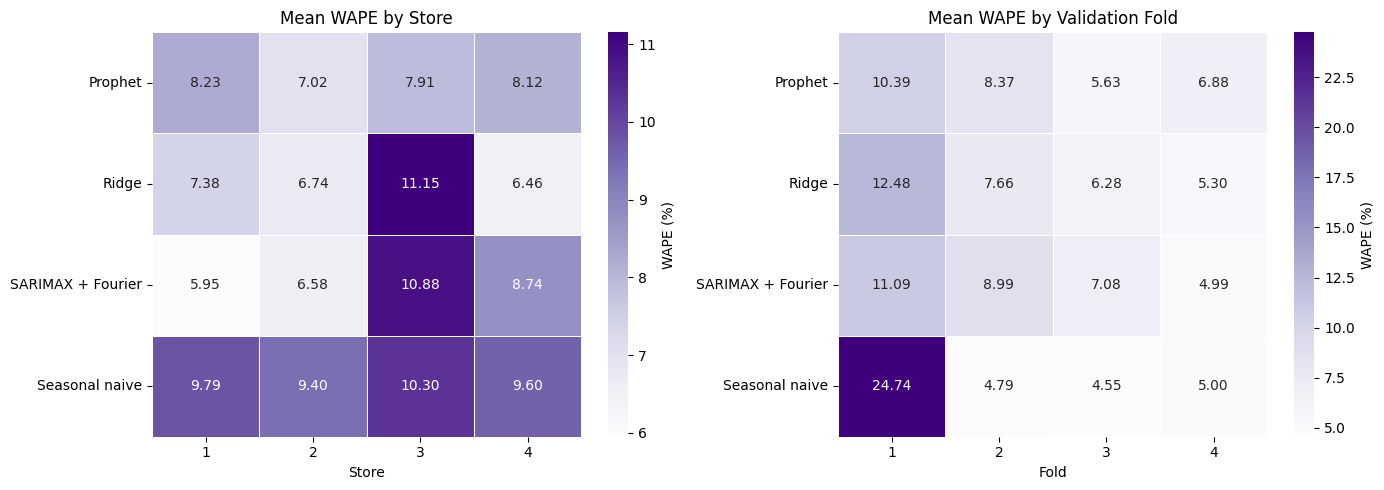

store_id,1,2,3,4
label,,,,
Prophet,8.229,7.020,7.906,8.115
Ridge,7.375,6.740,11.152,6.455
SARIMAX + Fourier,5.951,6.580,10.879,8.741
Seasonal naive,9.794,9.397,10.300,9.597


fold,1,2,3,4
label,,,,
Prophet,10.391,8.372,5.629,6.878
Ridge,12.484,7.655,6.283,5.301
SARIMAX + Fourier,11.094,8.994,7.077,4.987
Seasonal naive,24.744,4.793,4.553,5.000


Mean Prophet advantage: 0.113 pp
Prophet wins: 6 / 16
Ridge wins: 10 / 16
Ties: 0 / 16


label          Prophet   Ridge  SARIMAX + Fourier  Seasonal naive  \
fold store_id                                                       
1    1          10.962   9.762             10.131          27.530   
     2           7.380   7.420              9.350          21.040   
     3          13.508  21.836             16.673          24.394   
     4           9.716  10.916              8.220          26.010   
2    1           9.241   8.180              6.727           3.997   
     2           8.300   6.722              6.229           4.269   
     3           6.657  10.113             13.300           6.734   
     4           9.290   5.605              9.721           4.172   
3    1           6.458   6.157              3.616           3.968   
     2           6.160   7.145              5.580           6.036   
     3           3.264   7.577              8.871           4.118   
     4           6.635   4.252             10.241           4.088   
4    1           6.253   5.401              3.331           3.682   
     2           6.241   5.675              5.162           6.243   
     3           8.197   5.081              4.672           5.954   
     4           6.821   5.047              6.782           4.119   

label          Ridge_minus_Prophet_pp  
fold store_id                          
1    1                         -1.200  
     2                          0.040  
     3                          8.328  
     4                          1.200  
2    1                         -1.061  
     2                         -1.578  
     3                          3.456  
     4                         -3.685  
3    1                         -0.301  
     2                          0.985  
     3                          4.313  
     4                         -2.382  
4    1                         -0.853  
     2                         -0.566  
     3                         -3.116  
     4                         -1.774

In [3]:
shortlist = [
    (
        "Calendar / state space",
        "Prophet additive | cps=0.1 | calendar=False",
        "Prophet",
    ),
    (
        "Machine learning",
        "Ridge alpha=100",
        "Ridge",
    ),
    (
        "Calendar / state space",
        "SARIMAX log | annual K=1",
        "SARIMAX + Fourier",
    ),
    (
        "Classical",
        "Seasonal naive",
        "Seasonal naive",
    ),
]

selected_parts = []

for family, model, label in shortlist:
    part = all_scores.loc[
        (all_scores["family"] == family)
        & (all_scores["model"] == model)
    ].copy()

    assert len(part) == 16, f"Incomplete results: {model}"
    part["label"] = label
    selected_parts.append(part)

shortlist_scores = pd.concat(selected_parts, ignore_index=True)
label_order = [label for _, _, label in shortlist]

store_wape = (
    shortlist_scores.groupby(["label", "store_id"])["WAPE_pct"]
    .mean()
    .unstack("store_id")
    .reindex(label_order)
)

fold_wape = (
    shortlist_scores.groupby(["label", "fold"])["WAPE_pct"]
    .mean()
    .unstack("fold")
    .reindex(label_order)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, table, title, xlabel in [
    (axes[0], store_wape, "Mean WAPE by Store", "Store"),
    (axes[1], fold_wape, "Mean WAPE by Validation Fold", "Fold"),
]:
    sns.heatmap(
        table,
        annot=True,
        fmt=".2f",
        cmap="Purples",
        linewidths=0.5,
        cbar_kws={"label": "WAPE (%)"},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

display(store_wape.round(3))
display(fold_wape.round(3))

# Paired comparison on identical stores and folds.
paired_wape = shortlist_scores.pivot(
    index=["fold", "store_id"],
    columns="label",
    values="WAPE_pct",
)

# Positive values mean Prophet has lower error than Ridge.
paired_wape["Ridge_minus_Prophet_pp"] = (
    paired_wape["Ridge"] - paired_wape["Prophet"]
)

difference = paired_wape["Ridge_minus_Prophet_pp"]

print(f"Mean Prophet advantage: {difference.mean():.3f} pp")
print(f"Prophet wins: {(difference > 1e-6).sum()} / 16")
print(f"Ridge wins: {(difference < -1e-6).sum()} / 16")
print(f"Ties: {(difference.abs() <= 1e-6).sum()} / 16")

display(paired_wape.round(3))

store_wape.to_csv(RESULTS_DIR / "shortlist_store_wape.csv")
fold_wape.to_csv(RESULTS_DIR / "shortlist_fold_wape.csv")
paired_wape.to_csv(RESULTS_DIR / "shortlist_paired_wape.csv")

## 2. Final Model Selection

We select additive Prophet with changepoint prior scale 0.1 and
without additional calendar regressors. It achieves the lowest
mean WAPE across the 16 store–fold combinations (7.818%).

The advantage over Ridge is small (0.113 percentage points).
Ridge wins in 10 of the 16 paired comparisons and has lower
average errors for stores 1, 2, and 4. Prophet's overall advantage
is driven by larger improvements for store 3, particularly in
the first fold. We do not claim uniform or statistically
established superiority.

We retain one model specification for all stores. Each store
receives a separately fitted Prophet model using its complete
development history. Seasonal naive is retained as a benchmark.

We freeze this procedure before evaluating test targets.
Test results will be reported without further model selection,
bias correction, or hyperparameter tuning.

In [4]:
from importlib.metadata import version

with open(
    PROJECT_ROOT / "data" / "processed"
    / "retail_forecasting_config.json",
    encoding="utf-8",
) as file:
    config = json.load(file)

TEST_START = pd.Timestamp(config["test_start"])
TEST_END = pd.Timestamp(config["test_end"])
DEVELOPMENT_END = TEST_START - pd.Timedelta(days=1)

test_dates = pd.date_range(TEST_START, TEST_END, freq="D")
assert len(test_dates) == 28

selected_name = "Prophet additive | cps=0.1 | calendar=False"

assert eligible.iloc[0]["model"] == selected_name

selection = {
    "selected_model": selected_name,
    "selection_metric": "mean WAPE over 16 equally weighted store-folds",
    "development_end": str(DEVELOPMENT_END.date()),
    "test_start": str(TEST_START.date()),
    "test_end": str(TEST_END.date()),
    "horizon_days": 28,
    "separate_fit_per_store": True,
    "growth": "linear",
    "seasonality_mode": "additive",
    "changepoint_prior_scale": 0.1,
    "seasonality_prior_scale": 10.0,
    "n_changepoints": 15,
    "changepoint_range": 0.8,
    "weekly_period": 7,
    "weekly_fourier_order": 3,
    "yearly_seasonality": False,
    "daily_seasonality": False,
    "additional_regressors": [],
    "target_divisor": 1_000_000,
    "uncertainty_samples": 0,
    "prediction_clipping": False,
    "seed": 42,
    "benchmark": "Seasonal naive, repeating the last 7 days",
    "prophet_version": version("prophet"),
}

with open(
    RESULTS_DIR / "final_model_selection.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(selection, file, indent=2, ensure_ascii=False)

display(pd.Series(selection))

selected_model                Prophet additive | cps=0.1 | calendar=False
selection_metric           mean WAPE over 16 equally weighted store-folds
development_end                                                2024-08-29
test_start                                                     2024-08-30
test_end                                                       2024-09-26
horizon_days                                                           28
separate_fit_per_store                                               True
growth                                                             linear
seasonality_mode                                                 additive
changepoint_prior_scale                                               0.1
seasonality_prior_scale                                              10.0
n_changepoints                                                         15
changepoint_range                                                     0.8
weekly_period                         

In [5]:
from prophet import Prophet
from prophet.serialize import model_to_json

dev = pd.read_csv(
    PROJECT_ROOT / "data" / "processed"
    / "retail_daily_store_dev.csv",
    parse_dates=["date"],
)

assert dev["date"].max() == DEVELOPMENT_END
assert (dev["date"] < TEST_START).all()
assert not dev.duplicated(["store_id", "date"]).any()


def fill_training_gaps(series):
    raw = series.copy()
    filled = raw.copy()

    for date in raw.index[raw.isna()]:
        earlier = raw.loc[raw.index < date].dropna()
        same_weekday = earlier.loc[
            earlier.index.dayofweek == date.dayofweek
        ].tail(8)

        if len(same_weekday):
            filled.loc[date] = same_weekday.median()
        elif len(earlier):
            filled.loc[date] = earlier.iloc[-1]
        else:
            raise ValueError(f"No past observations for {date}")

    assert np.isfinite(filled.to_numpy()).all()
    return filled


forecast_parts = []

for store_id in sorted(dev["store_id"].unique()):
    raw = (
        dev.loc[dev["store_id"] == store_id]
        .set_index("date")["y"]
        .sort_index()
        .asfreq("D")
    )

    assert raw.index[-1] == DEVELOPMENT_END
    train = fill_training_gaps(raw)

    model = Prophet(
        growth="linear",
        seasonality_mode="additive",
        changepoint_prior_scale=0.1,
        seasonality_prior_scale=10.0,
        weekly_seasonality=False,
        yearly_seasonality=False,
        daily_seasonality=False,
        n_changepoints=15,
        changepoint_range=0.8,
        uncertainty_samples=0,
    )

    model.add_seasonality(
        name="weekly",
        period=7,
        fourier_order=3,
    )

    model.fit(
        pd.DataFrame({
            "ds": train.index,
            "y": train.to_numpy() / 1_000_000,
        }),
        seed=42,
    )

    prediction = (
        model.predict(pd.DataFrame({"ds": test_dates}))["yhat"]
        .to_numpy() * 1_000_000
    )

    # Benchmark uses only the last observed training week.
    last_week = raw.iloc[-7:].to_numpy()
    assert np.isfinite(last_week).all()
    baseline = np.tile(last_week, 4)

    assert np.isfinite(prediction).all()

    for model_name, values in [
        (selected_name, prediction),
        ("Seasonal naive", baseline),
    ]:
        forecast_parts.append(pd.DataFrame({
            "model": model_name,
            "store_id": store_id,
            "date": test_dates,
            "horizon_step": np.arange(1, 29),
            "prediction": values,
        }))

    with open(
        RESULTS_DIR / f"final_prophet_store_{store_id}.json",
        "w",
        encoding="utf-8",
    ) as file:
        file.write(model_to_json(model))

    print(f"Store {store_id}: fitted and forecast saved.")

test_forecasts = pd.concat(forecast_parts, ignore_index=True)

assert len(test_forecasts) == 2 * 4 * 28
assert not test_forecasts.duplicated(
    ["model", "store_id", "date"]
).any()

test_forecasts.to_csv(
    RESULTS_DIR / "frozen_test_forecasts.csv",
    index=False,
)

display(
    test_forecasts.groupby(["model", "store_id"])
    .agg(
        forecast_days=("date", "size"),
        predicted_total=("prediction", "sum"),
    )
)

print("Forecasts saved. Test targets have not been loaded.")

18:59:19 - cmdstanpy - INFO - Chain [1] start processing
18:59:20 - cmdstanpy - INFO - Chain [1] done processing


Store 1: fitted and forecast saved.


18:59:20 - cmdstanpy - INFO - Chain [1] start processing
18:59:20 - cmdstanpy - INFO - Chain [1] done processing


Store 2: fitted and forecast saved.


18:59:21 - cmdstanpy - INFO - Chain [1] start processing
18:59:21 - cmdstanpy - INFO - Chain [1] done processing


Store 3: fitted and forecast saved.


18:59:21 - cmdstanpy - INFO - Chain [1] start processing
18:59:22 - cmdstanpy - INFO - Chain [1] done processing


Store 4: fitted and forecast saved.


forecast_days  \
model                                       store_id                  
Prophet additive | cps=0.1 | calendar=False 1                    28   
                                            2                    28   
                                            3                    28   
                                            4                    28   
Seasonal naive                              1                    28   
                                            2                    28   
                                            3                    28   
                                            4                    28   

                                                      predicted_total  
model                                       store_id                   
Prophet additive | cps=0.1 | calendar=False 1            1.182538e+08  
                                            2            1.794048e+07  
                                            3            2.864455e+07  
                                            4            1.444528e+08  
Seasonal naive                              1            1.178693e+08  
                                            2            1.894830e+07  
                                            3            2.686650e+07  
                                            4            1.402491e+08

Forecasts saved. Test targets have not been loaded.


## 3. Final Test Evaluation

We evaluate the frozen Prophet and seasonal-naive forecasts for
30 August–26 September 2024.

Actual sales are aggregated using the same target definition as
during development: daily sums of recorded `sum_total` by store.
We retain recorded adjustments and do not add online sales.

Our primary test metric is mean WAPE across the four stores,
giving each store equal weight. We also report individual store
metrics and pooled WAPE, which assigns more weight to stores
with larger absolute sales totals.

Test outcomes are used for final reporting, without further
model selection or tuning.

In [6]:
# Read the saved forecasts rather than generating new predictions.
frozen = pd.read_csv(
    RESULTS_DIR / "frozen_test_forecasts.csv",
    parse_dates=["date"],
)

assert len(frozen) == 224
assert np.isfinite(frozen["prediction"]).all()
assert not frozen.duplicated(
    ["model", "store_id", "date"]
).any()

expected_stores = sorted(dev["store_id"].unique())
expected_keys = {
    (store_id, date)
    for store_id in expected_stores
    for date in test_dates
}

for model_name, part in frozen.groupby("model"):
    assert set(zip(part["store_id"], part["date"])) == expected_keys

sales_path = PROJECT_ROOT / "data" / "raw" / "retail" / "sales.csv"
actual_parts = []

for chunk in pd.read_csv(
    sales_path,
    usecols=["date", "store_id", "sum_total"],
    dtype={
        "store_id": "int64",
        "sum_total": "float64",
    },
    chunksize=250_000,
):
    chunk["date"] = pd.to_datetime(
        chunk["date"],
        format="%Y-%m-%d",
        errors="raise",
    )

    part = chunk.loc[
        chunk["date"].between(TEST_START, TEST_END)
        & chunk["store_id"].isin(expected_stores)
    ].copy()

    if part.empty:
        continue

    assert np.isfinite(part["sum_total"]).all()

    actual_parts.append(
        part.groupby(["store_id", "date"])["sum_total"]
        .sum(min_count=1)
        .reset_index()
    )

assert actual_parts, "No test sales found."

test_actuals = (
    pd.concat(actual_parts, ignore_index=True)
    .groupby(["store_id", "date"])["sum_total"]
    .sum(min_count=1)
    .rename("actual")
    .reset_index()
)

assert set(
    zip(test_actuals["store_id"], test_actuals["date"])
) == expected_keys, "Missing store–date observations in test data."

assert np.isfinite(test_actuals["actual"]).all()

test_results = frozen.merge(
    test_actuals,
    on=["store_id", "date"],
    how="left",
    validate="many_to_one",
)

assert test_results["actual"].notna().all()

test_results["error"] = (
    test_results["prediction"] - test_results["actual"]
)
test_results["absolute_error"] = test_results["error"].abs()

print(
    f"Test actuals: {len(test_actuals)} store–days; "
    f"{test_actuals['date'].min().date()} to "
    f"{test_actuals['date'].max().date()}."
)

Test actuals: 112 store–days; 2024-08-30 to 2024-09-26.


In [7]:
test_score_rows = []

for (model_name, store_id), part in test_results.groupby(
    ["model", "store_id"]
):
    actual = part["actual"].to_numpy()
    error = part["error"].to_numpy()
    denominator = np.abs(actual).sum()

    assert len(part) == 28
    assert denominator > 0

    test_score_rows.append({
        "model": model_name,
        "store_id": store_id,
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "WAPE_pct": 100 * np.abs(error).sum() / denominator,
        "bias_pct": 100 * error.sum() / denominator,
        "actual_total": actual.sum(),
        "predicted_total": part["prediction"].sum(),
    })

test_scores = pd.DataFrame(test_score_rows)

test_summary = (
    test_scores.groupby("model")
    .agg(
        mean_store_WAPE_pct=("WAPE_pct", "mean"),
        worst_store_WAPE_pct=("WAPE_pct", "max"),
        mean_store_bias_pct=("bias_pct", "mean"),
        evaluated_stores=("store_id", "nunique"),
    )
)

for model_name, part in test_results.groupby("model"):
    denominator = part["actual"].abs().sum()

    test_summary.loc[model_name, "pooled_WAPE_pct"] = (
        100 * part["absolute_error"].sum() / denominator
    )

display(test_scores.round(3))
display(test_summary.round(3))

paired_test = test_scores.pivot(
    index="store_id",
    columns="model",
    values="WAPE_pct",
)

paired_test["Prophet_improvement_pp"] = (
    paired_test["Seasonal naive"] - paired_test[selected_name]
)

display(paired_test.round(3))

test_actuals.to_csv(
    RESULTS_DIR / "test_actuals.csv", index=False
)
test_results.to_csv(
    RESULTS_DIR / "final_test_predictions_and_errors.csv",
    index=False,
)
test_scores.to_csv(
    RESULTS_DIR / "final_test_store_scores.csv", index=False
)
test_summary.to_csv(
    RESULTS_DIR / "final_test_summary.csv"
)
paired_test.to_csv(
    RESULTS_DIR / "final_test_baseline_comparison.csv"
)

,model,store_id,MAE,RMSE,WAPE_pct,bias_pct,actual_total,predicted_total
0,Prophet additive | cps=0.1 | calendar=False,1,252950.924,395925.212,5.762,-3.803,1.229285e+08,1.182538e+08
1,Prophet additive | cps=0.1 | calendar=False,2,76898.565,88469.681,10.716,-10.716,2.009364e+07,1.794048e+07
2,Prophet additive | cps=0.1 | calendar=False,3,73712.049,86699.245,7.761,7.707,2.659488e+07,2.864455e+07
3,Prophet additive | cps=0.1 | calendar=False,4,307321.515,407598.733,6.248,4.891,1.377166e+08,1.444528e+08
4,Seasonal naive,1,256610.190,351540.394,5.845,-4.116,1.229285e+08,1.178693e+08
5,Seasonal naive,2,46094.782,65999.349,6.423,-5.700,2.009364e+07,1.894830e+07
6,Seasonal naive,3,35037.041,46840.876,3.689,1.021,2.659488e+07,2.686650e+07
7,Seasonal naive,4,395094.005,576720.062,8.033,1.839,1.377166e+08,1.402491e+08


,mean_store_WAPE_pct,worst_store_WAPE_pct,mean_store_bias_pct,evaluated_stores,pooled_WAPE_pct
model,,,,,
Prophet additive | cps=0.1 | calendar=False,7.622,10.716,-0.480,4,6.477
Seasonal naive,5.997,8.033,-1.739,4,6.677


model,Prophet additive | cps=0.1 | calendar=False,Seasonal naive,Prophet_improvement_pp
store_id,,,
1,5.762,5.845,0.083
2,10.716,6.423,-4.292
3,7.761,3.689,-4.072
4,6.248,8.033,1.785


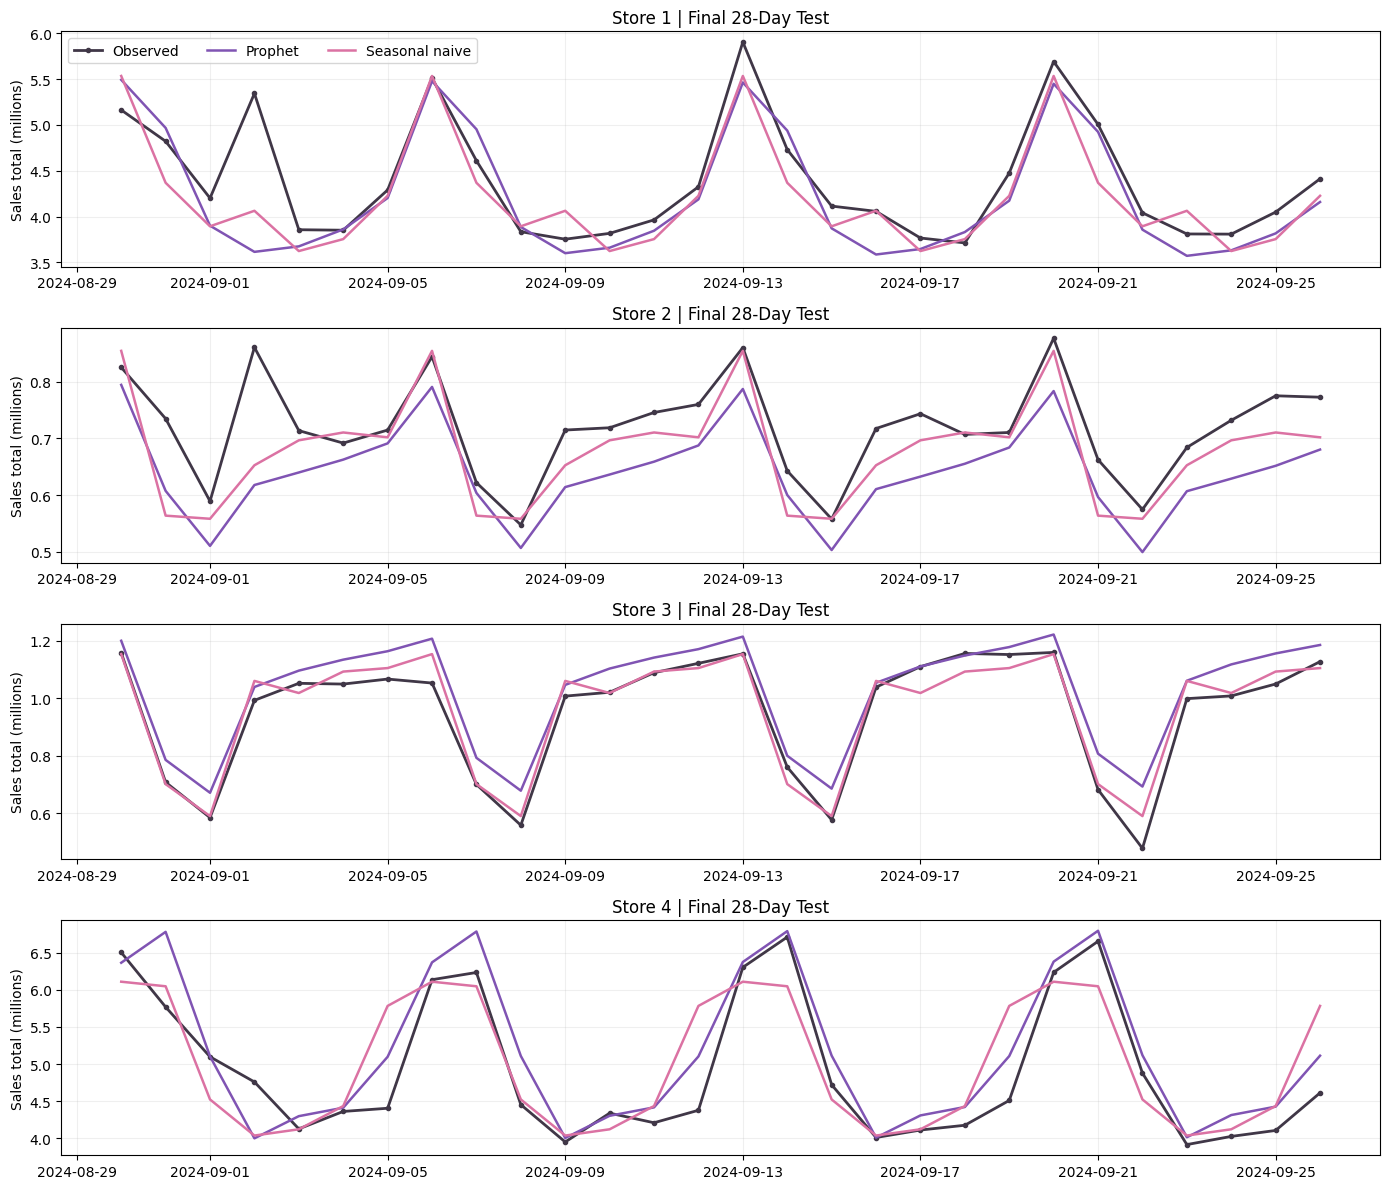

In [8]:
plot_labels = {
    selected_name: "Prophet",
    "Seasonal naive": "Seasonal naive",
}
plot_colors = {
    selected_name: "#8054B3",
    "Seasonal naive": "#DB72A3",
}

fig, axes = plt.subplots(
    len(expected_stores), 1,
    figsize=(14, 12),
    squeeze=False,
)

for ax, store_id in zip(axes.ravel(), expected_stores):
    actual = (
        test_actuals.loc[test_actuals["store_id"] == store_id]
        .sort_values("date")
    )

    ax.plot(
        actual["date"],
        actual["actual"] / 1e6,
        color="#403747",
        linewidth=2,
        marker="o",
        markersize=3,
        label="Observed",
    )

    for model_name in plot_labels:
        part = test_results.loc[
            (test_results["store_id"] == store_id)
            & (test_results["model"] == model_name)
        ].sort_values("date")

        ax.plot(
            part["date"],
            part["prediction"] / 1e6,
            color=plot_colors[model_name],
            linewidth=1.8,
            label=plot_labels[model_name],
        )

    ax.set_title(f"Store {store_id} | Final 28-Day Test")
    ax.set_ylabel("Sales total (millions)")
    ax.grid(alpha=0.2)

axes[0, 0].legend(ncol=3)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "final_test_forecasts.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

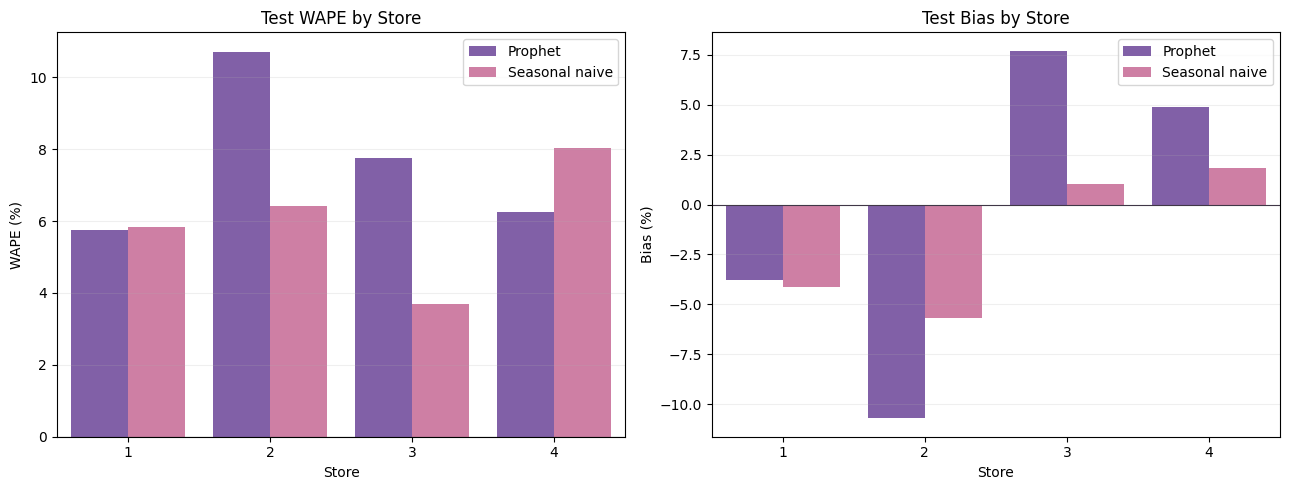

In [9]:
plot_scores = test_scores.copy()
plot_scores["method"] = plot_scores["model"].map(plot_labels)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric, title in [
    (axes[0], "WAPE_pct", "Test WAPE by Store"),
    (axes[1], "bias_pct", "Test Bias by Store"),
]:
    sns.barplot(
        data=plot_scores,
        x="store_id",
        y=metric,
        hue="method",
        hue_order=["Prophet", "Seasonal naive"],
        palette=["#8054B3", "#DB72A3"],
        errorbar=None,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Store")
    ax.set_ylabel("WAPE (%)" if metric == "WAPE_pct" else "Bias (%)")
    ax.axhline(0, color="#403747", linewidth=0.8)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(title="")

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "final_test_metrics.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 4. Final Test Findings

The selected Prophet pipeline achieves mean store-level test WAPE
of 7.622%, compared with 5.997% for seasonal naive. It therefore
does not outperform the benchmark under our primary evaluation
criterion, despite having the lowest mean cross-validation WAPE.

Performance differs across stores. Prophet improves WAPE for stores
1 and 4 by 0.083 and 1.785 percentage points, respectively, but
performs worse for stores 2 and 3 by 4.292 and 4.072 percentage points.

Pooled WAPE gives a different ordering: 6.477% for Prophet versus
6.677% for seasonal naive. This metric gives greater weight to
stores with larger absolute sales totals. We retain equal-store
mean WAPE as the primary metric rather than changing the criterion
after observing test outcomes.

Prophet's mean store-level bias is close to zero (-0.480%), but
this average conceals substantial errors in opposite directions.
Store 2 is underpredicted (bias -10.716%), while store 3 is
overpredicted (bias +7.707%).

The test results show that cross-validation leadership did not
translate into an advantage over seasonal naive on this particular
28-day period. They do not establish which method will perform best
over a full year or under different trading conditions.

We report the frozen forecasts without post-test tuning, model
replacement, or bias correction. The strong seasonal-naive result
emphasizes the importance of retaining simple benchmarks.